In [65]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [66]:
wines = pd.read_csv("WineQT.csv")

In [3]:
wines.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1143 entries, 0 to 1142
Data columns (total 13 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   fixed acidity         1143 non-null   float64
 1   volatile acidity      1143 non-null   float64
 2   citric acid           1143 non-null   float64
 3   residual sugar        1143 non-null   float64
 4   chlorides             1143 non-null   float64
 5   free sulfur dioxide   1143 non-null   float64
 6   total sulfur dioxide  1143 non-null   float64
 7   density               1143 non-null   float64
 8   pH                    1143 non-null   float64
 9   sulphates             1143 non-null   float64
 10  alcohol               1143 non-null   float64
 11  quality               1143 non-null   int64  
 12  Id                    1143 non-null   int64  
dtypes: float64(11), int64(2)
memory usage: 116.2 KB


In [4]:
wines.head()

,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality,Id
0,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5,0
1,7.8,0.88,0.00,2.6,0.098,25.0,67.0,0.9968,3.20,0.68,9.8,5,1
2,7.8,0.76,0.04,2.3,0.092,15.0,54.0,0.9970,3.26,0.65,9.8,5,2
3,11.2,0.28,0.56,1.9,0.075,17.0,60.0,0.9980,3.16,0.58,9.8,6,3
4,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5,4


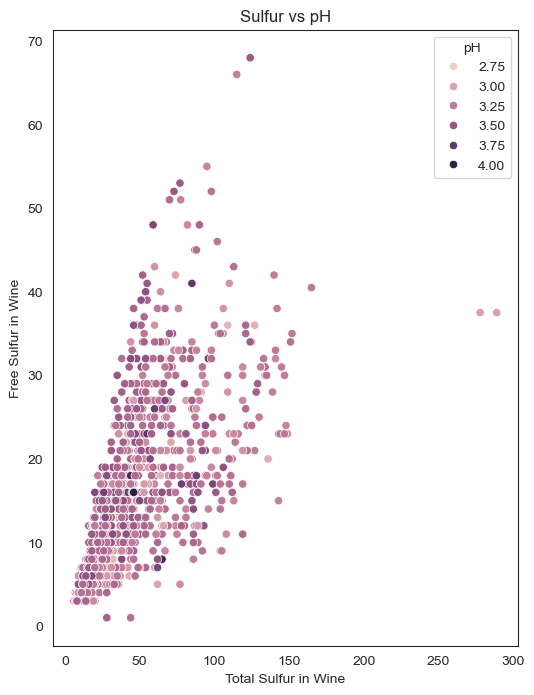

In [16]:
sns.set_style("white")
plt.figure(figsize=(6,8))
sns.scatterplot(x="total sulfur dioxide" , y= "free sulfur dioxide", hue="pH", data = wines)
plt.xlabel("Total Sulfur in Wine")
plt.ylabel("Free Sulfur in Wine")
plt.title("Sulfur vs pH")

plt.show()

Text(0.5, 1.0, 'pH VS Sulfur Dioxide')

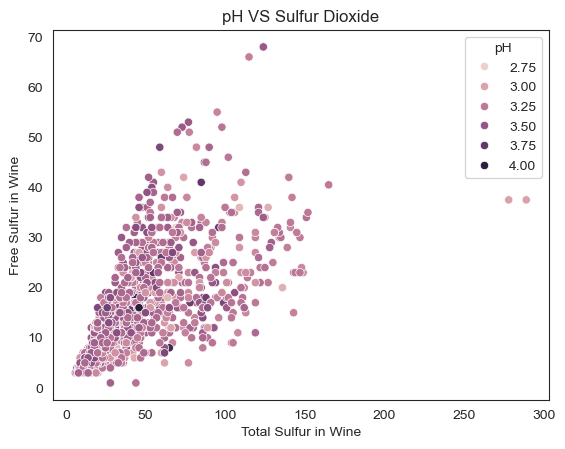

In [46]:
sns.set_style("white")
sns.scatterplot(x= "total sulfur dioxide", y=  "free sulfur dioxide", hue="pH", data = wines)
plt.xlabel("Total Sulfur in Wine")
plt.ylabel("Free Sulfur in Wine")
plt.title("pH VS Sulfur Dioxide")

<Axes: >

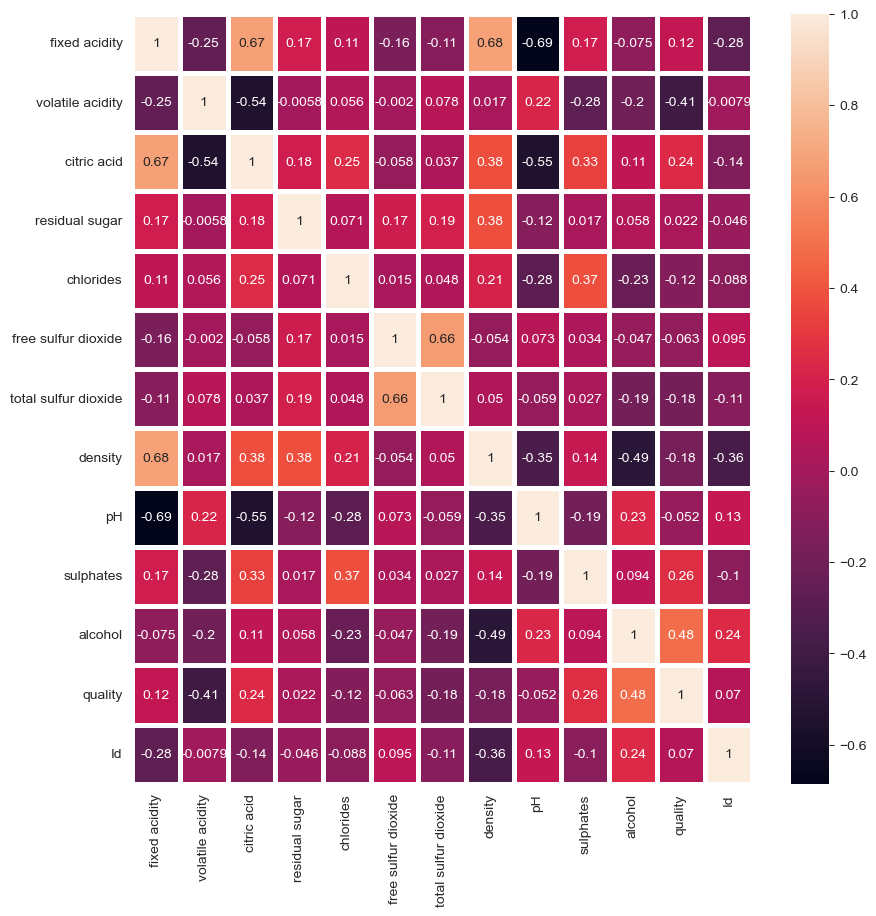

In [32]:
plt.figure(figsize=(10,10))
sns.heatmap(wines.corr(numeric_only= True), annot= True , linewidths= 2.5)

Fixed acidity and pH show a negative correlation (-0.69).
Fixed acidity and density show a strong positive correlation (0.68).
Volatile acidity and citric acid show a negative correlation (-0.54).
Fixed acidity and citric acid show a positive correlation.
Free sulfur dioxide and total sulfur dioxide show a strong positive correlation (0.66).
Alcohol and density show a negative correlation (-0.49).
Alcohol and quality show a positive correlation.

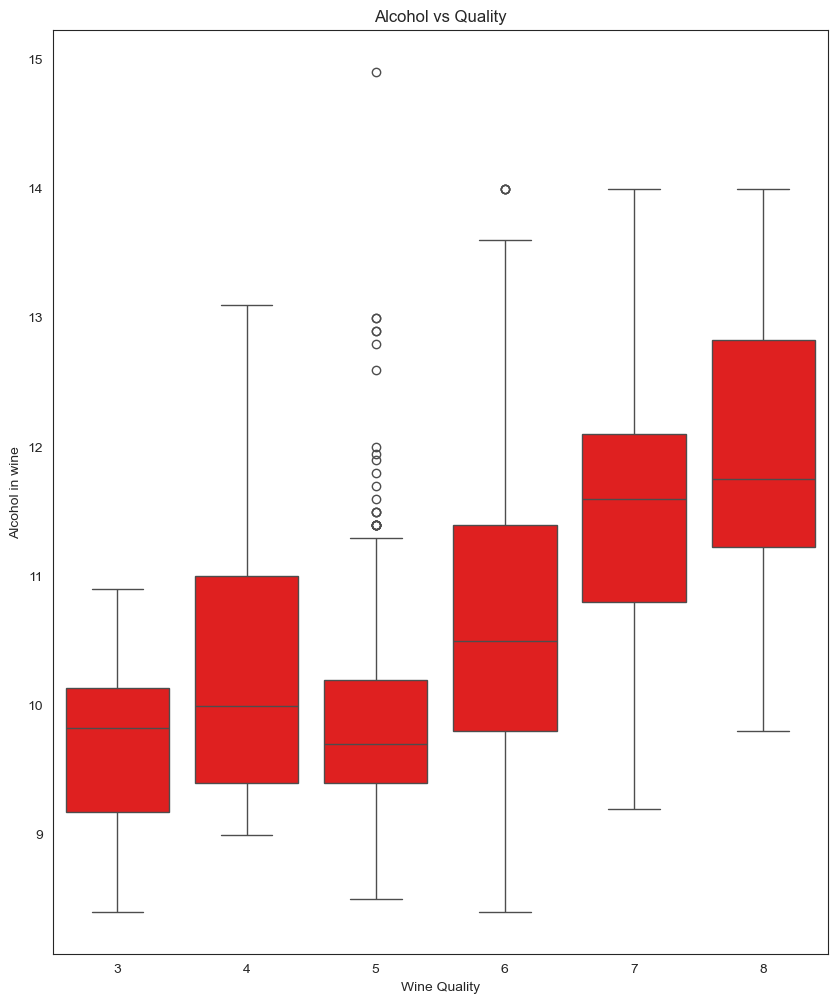

In [35]:
plt.figure(figsize=(10,12))

sns.boxplot(x= "quality", y = "alcohol", color = "red" , data= wines)
plt.xlabel("Wine Quality")
plt.ylabel("Alcohol in wine")
plt.title("Alcohol vs Quality")

plt.show()


We observed a positive correlation between alcohol and wine quality. We tested this relationship with a boxplot, but the results showed that increasing alcohol content alone does not necessarily increase wine quality.

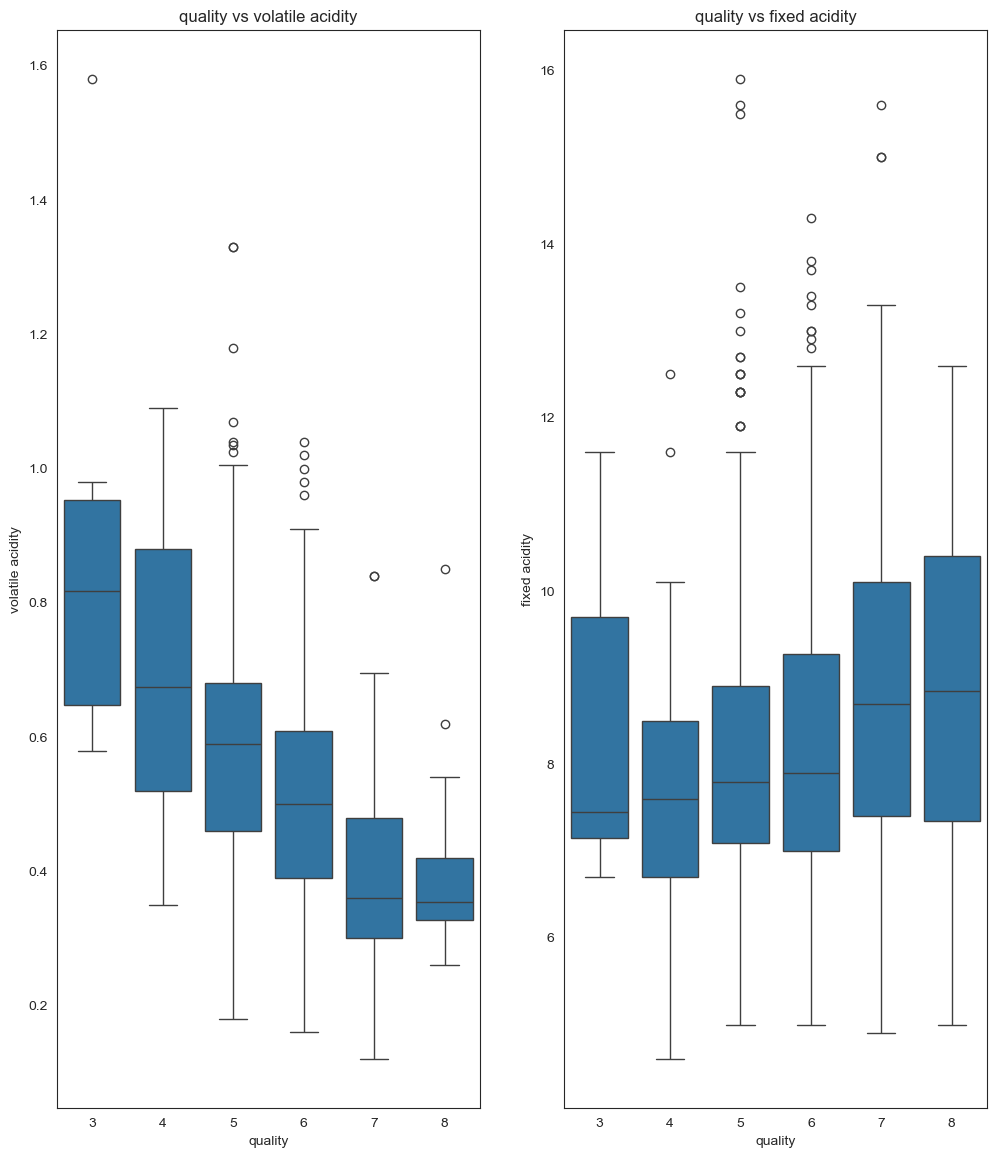

In [39]:
plt.figure(figsize=(12,14))

plt.subplot(1,2,1)
sns.boxplot(x="quality", y="volatile acidity" , data= wines)
plt.title("quality vs volatile acidity")
plt.xlabel("quality")
plt.ylabel("volatile acidity")

plt.subplot(1,2,2)
sns.boxplot(x="quality" , y= "fixed acidity" , data=wines)
plt.title("quality vs fixed acidity")
plt.xlabel("quality")
plt.ylabel("fixed acidity")

plt.show()

As wine quality increases, volatile acidity generally tends to decrease. However, the relationship between fixed acidity and quality is less consistent.

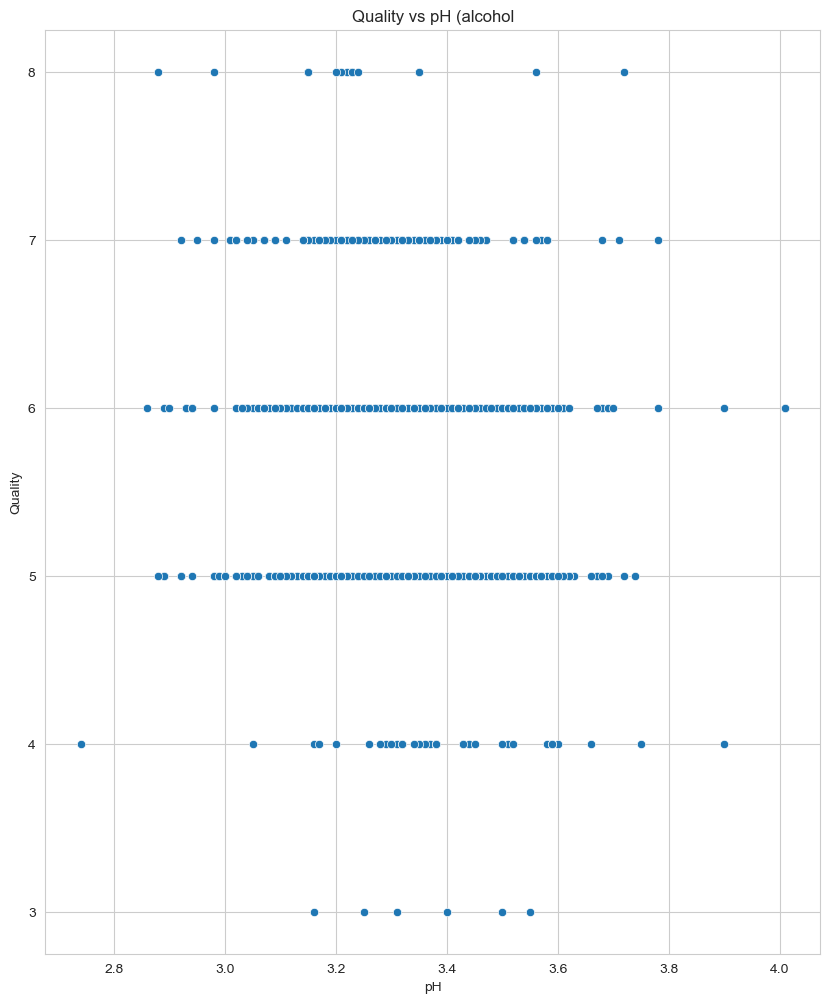

In [43]:
plt.figure(figsize=(10,12))

sns.set_style("whitegrid")
sns.scatterplot(x="pH", y="quality", data= wines)
plt.ylabel("Quality")
plt.xlabel("pH")
plt.title("Quality vs pH (alcohol)")

plt.show()

In [47]:
wines.groupby("quality").mean()

,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,Id
quality,,,,,,,,,,,,
3,8.450000,0.897500,0.211667,2.666667,0.105333,8.166667,24.500000,0.997682,3.361667,0.550000,9.691667,1121.166667
4,7.809091,0.700000,0.165758,2.566667,0.094788,14.848485,40.606061,0.996669,3.391212,0.637879,10.260606,692.848485
5,8.161077,0.585280,0.240124,2.540476,0.091770,16.612836,55.299172,0.997073,3.302091,0.613375,9.902277,753.925466
6,8.317749,0.504957,0.263680,2.444805,0.085281,15.215368,39.941558,0.996610,3.323788,0.676537,10.655339,854.625541
7,8.851049,0.393671,0.386573,2.760140,0.075217,14.538462,37.489510,0.996071,3.287133,0.743566,11.482634,830.349650
8,8.806250,0.410000,0.432500,2.643750,0.070187,11.062500,29.375000,0.995553,3.240625,0.766250,11.937500,797.875000


<Axes: xlabel='quality'>

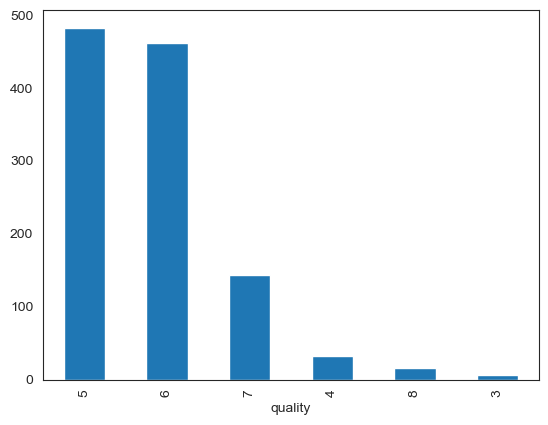

In [49]:
wines["quality"].value_counts().plot(kind="bar")

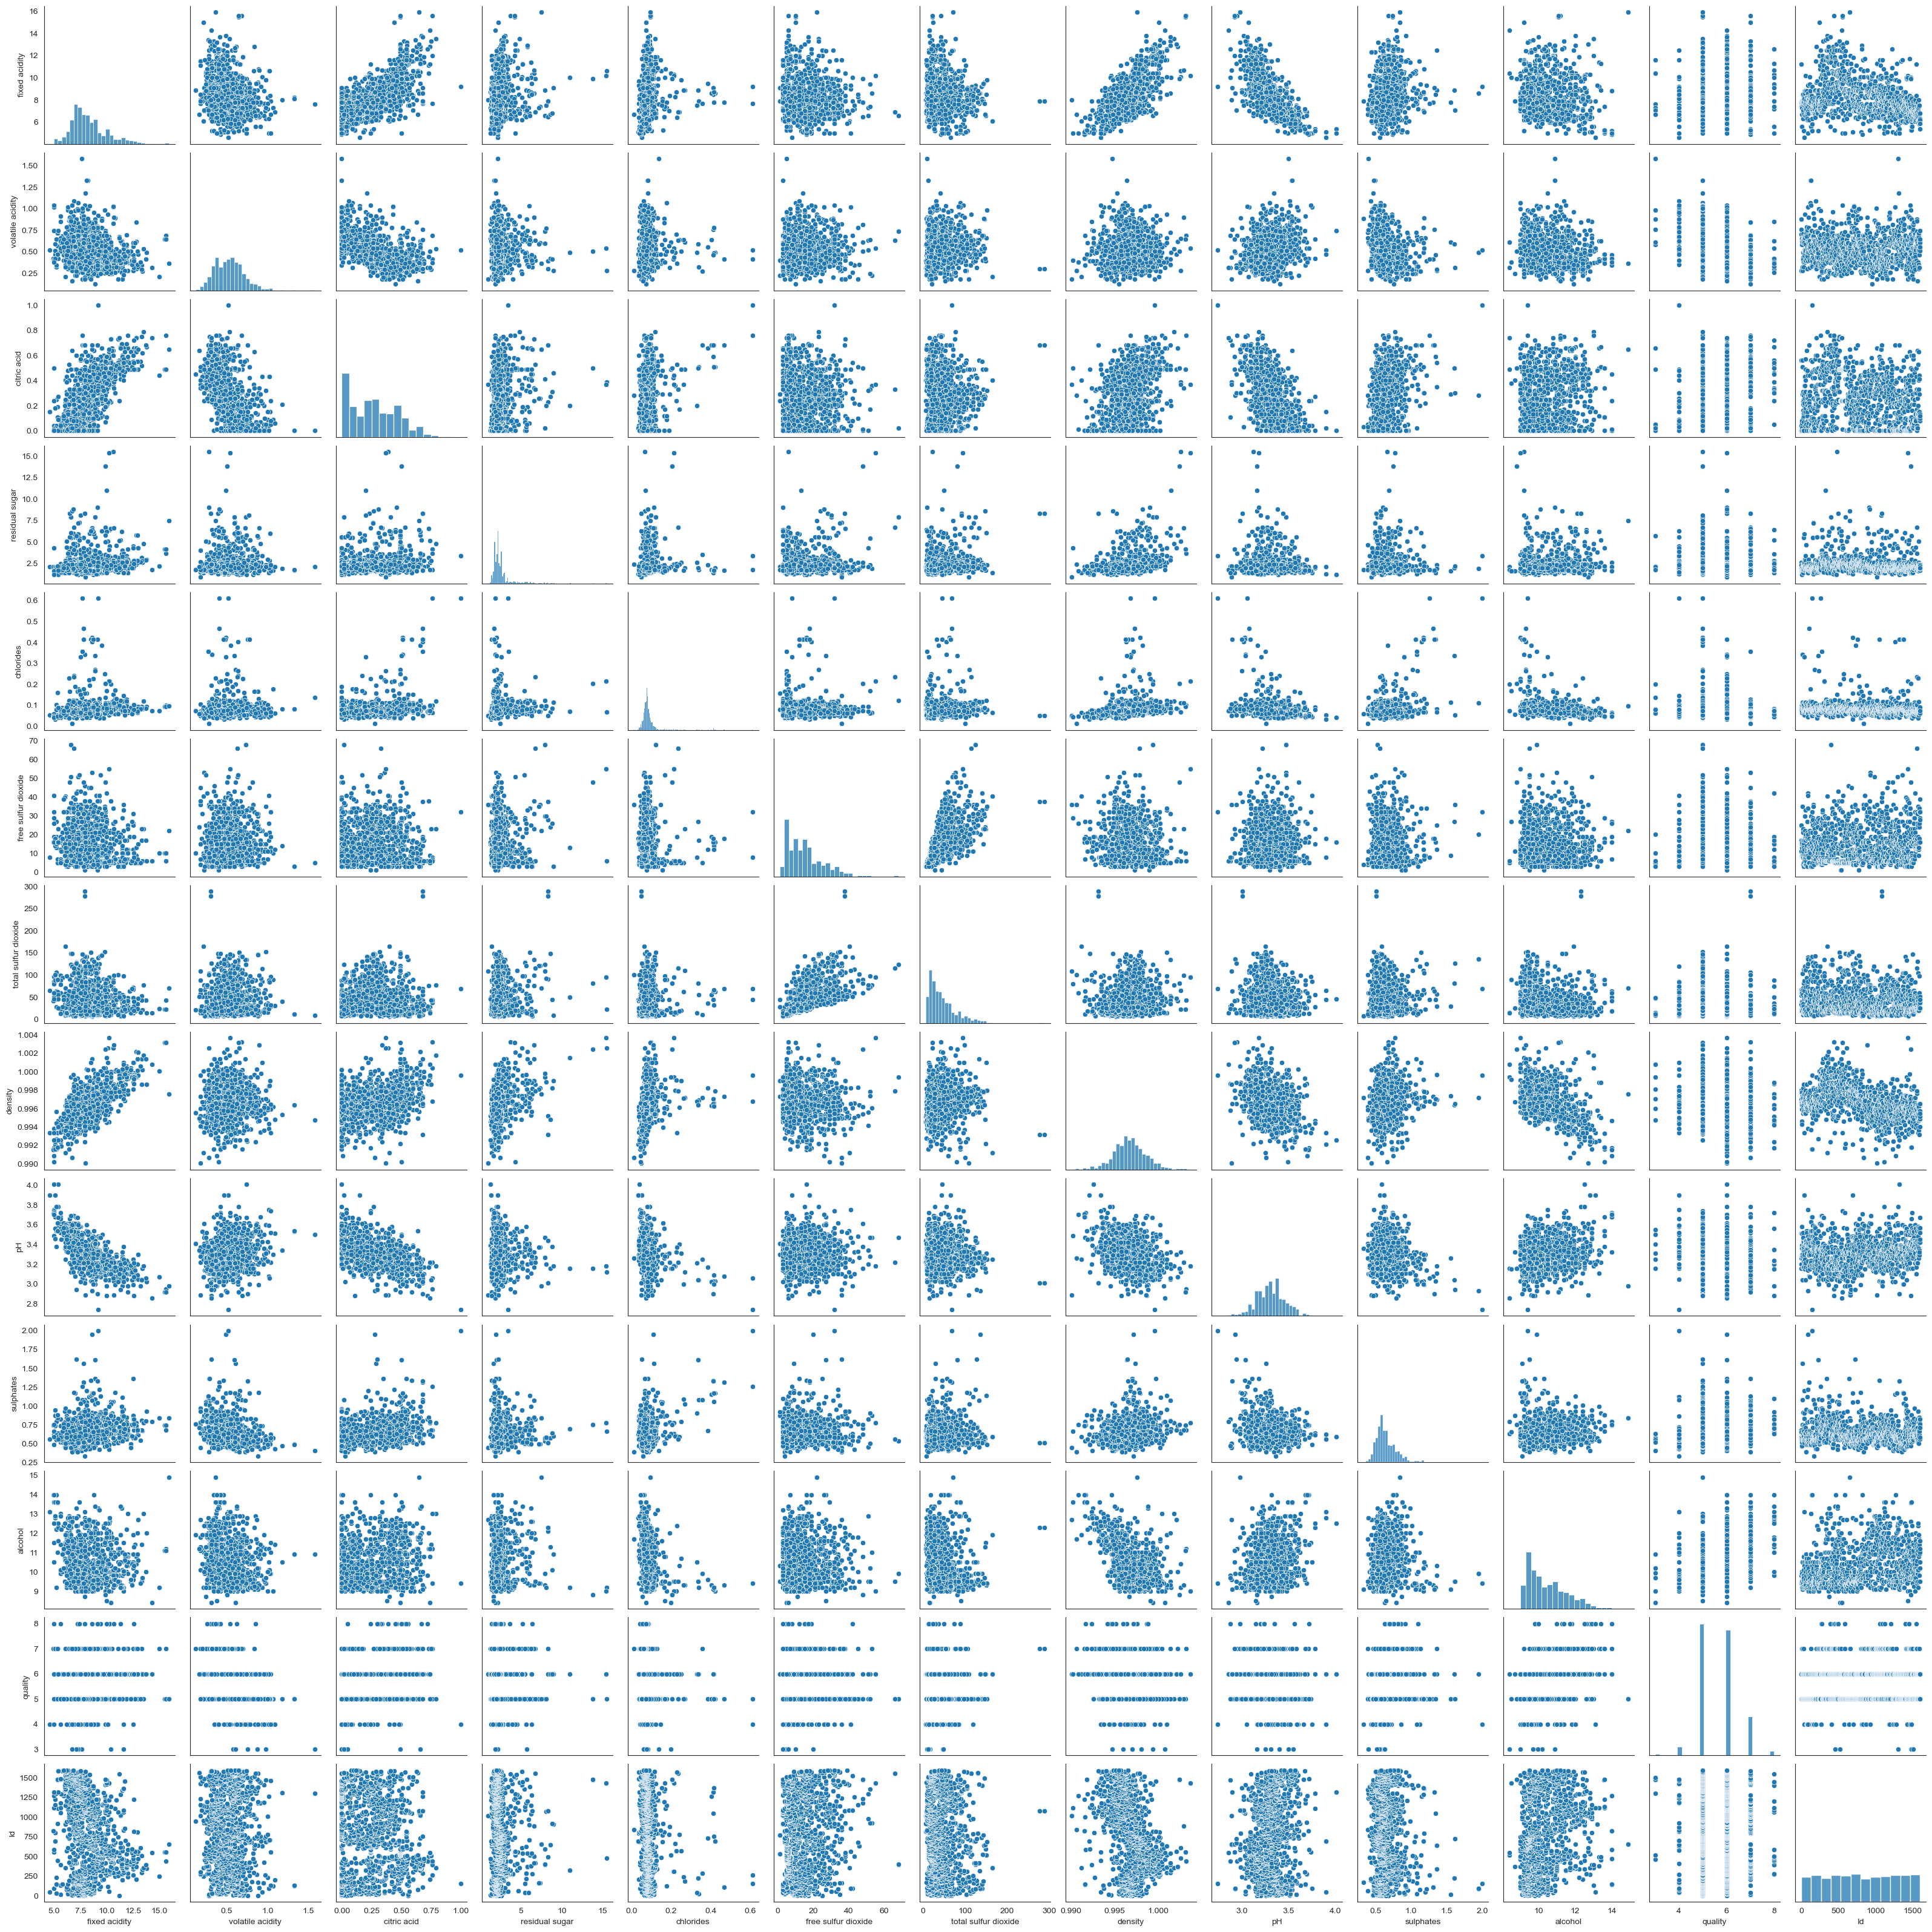

In [50]:
sns.pairplot(wines)

In [68]:
wines.drop("Id", axis=1, inplace = True)

/var/folders/2z/j982lrws7fn3d4rpszl6hcdc0000gn/T/ipykernel_63775/384240384.py:6: UserWarning: Dataset has 0 variance; skipping density estimate. Pass `warn_singular=False` to disable this warning.
  sns.kdeplot(


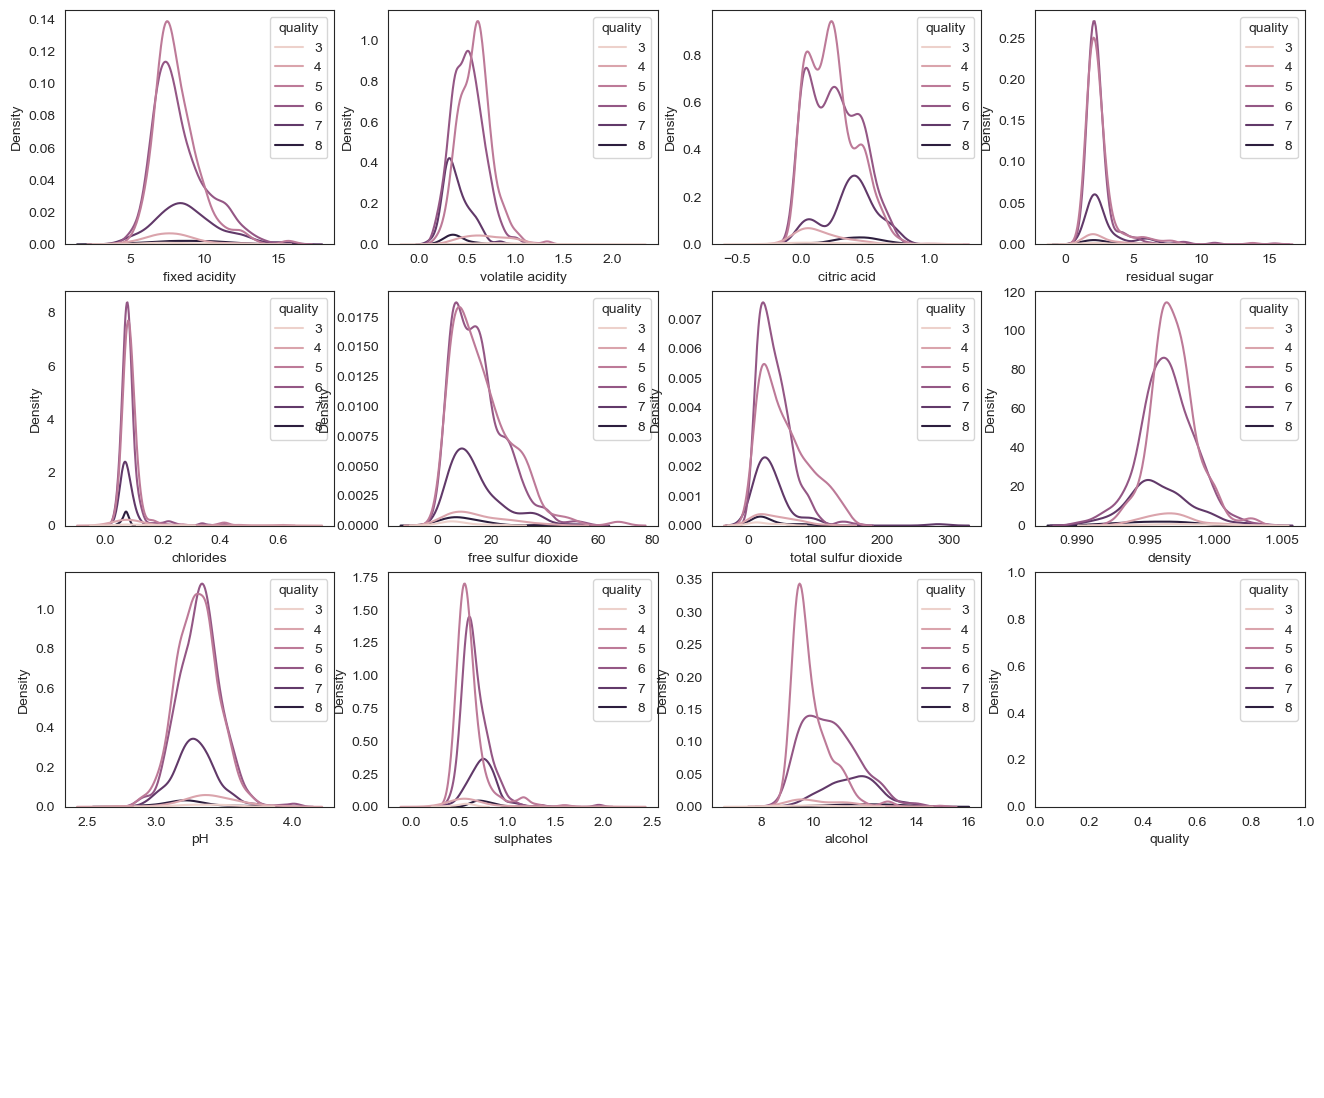

In [72]:
columns = wines.columns
(fig,ax) = plt.subplots(4,4, figsize=(16,14))
ax = ax.flatten() #çoklu liste içinde geldiği için hata veriyordu 

for i, column in enumerate(columns):
    sns.kdeplot(
        data = wines,
        x = column,
        hue = wines.quality , # & wines["quality"]
        ax = ax[i]
    )
for i in range(i+1, len(ax)):
    ax[i].axis("off")